# Decomposing Private Equity

**FINM 36700 · Homework 3 · Group 22**
Lucas Albín Lazcano, Avi Rastogi, Mengting Wang, and Yihan Kong

_Acknowledgements: Claude Opus 5.5 was used to set up the submission structure as well as help with coding the solutions to the problems._

## Data

Use the data in `data/private_equity_data.xlsx`.

We use the `excess returns` sheet (returns over `SHV`, short-term treasuries), so means, Sharpe ratios and alphas are all relative to the risk-free rate. Everything is annualized with 52 weeks.

In [9]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

FILE = "private_equity_data.xlsx"
info = pd.read_excel(FILE, sheet_name="descriptions").set_index("ticker")
xs = pd.read_excel(FILE, sheet_name="excess returns").set_index("date")

print(f"{xs.index[0]:%Y-%m-%d} to {xs.index[-1]:%Y-%m-%d}, {len(xs)} weeks")
info[["shortName", "quoteType"]]

2015-01-09 to 2025-10-03, 561 weeks


,shortName,quoteType
ticker,,
SPY,SPDR S&P 500,ETF
VTV,Vanguard Value ETF,ETF
AGG,iShares Core U.S. Aggregate Bon,ETF
HYG,iShares iBoxx $ High Yield Corp,ETF
IEF,iShares 7-10 Year Treasury Bond,ETF
PSP,Invesco Global Listed Private E,ETF
PEX,ProShares Global Listed Private,ETF
APO,"Apollo Global Management, Inc.",EQUITY
BX,Blackstone Inc.,EQUITY


# 1. Performance

Calculate performance stats for the assets, both stand-alone (mean, vol, Sharpe) as well as linear decompositions (alpha, beta, info ratio, r-squared).

In [10]:
stand_alone = pd.DataFrame({
    "Mean": xs.mean() * 52,
    "Vol": xs.std() * np.sqrt(52),
})
stand_alone["Sharpe"] = stand_alone["Mean"] / stand_alone["Vol"]

stand_alone.style.format({"Mean": "{:.2%}", "Vol": "{:.2%}", "Sharpe": "{:.2f}"})

,Mean,Vol,Sharpe
SPY,12.31%,16.97%,0.73
VTV,8.65%,16.41%,0.53
AGG,-0.79%,5.09%,-0.15
HYG,-0.47%,9.54%,-0.05
IEF,-0.73%,6.44%,-0.11
PSP,4.94%,23.17%,0.21
PEX,-1.43%,21.46%,-0.07
APO,23.15%,36.79%,0.63
BX,21.76%,35.82%,0.61
KKR,22.86%,36.50%,0.63


In [11]:
# regress each asset on SPY
rows = {}
for asset in xs.columns.drop("SPY"):
    fit = sm.OLS(xs[asset], sm.add_constant(xs["SPY"])).fit()
    alpha = fit.params["const"] * 52
    te = fit.resid.std() * np.sqrt(52)
    rows[asset] = {
        "Alpha": alpha,
        "Beta": fit.params["SPY"],
        "Info ratio": alpha / te,
        "R-squared": fit.rsquared,
        "Alpha t-stat": fit.tvalues["const"],
    }

decomp = pd.DataFrame(rows).T
decomp.style.format({"Alpha": "{:.2%}", "Beta": "{:.2f}", "Info ratio": "{:.2f}",
                     "R-squared": "{:.2f}", "Alpha t-stat": "{:.2f}"})

,Alpha,Beta,Info ratio,R-squared,Alpha t-stat
VTV,-2.39%,0.90,-0.39,0.86,-1.27
AGG,-1.60%,0.07,-0.32,0.05,-1.05
HYG,-5.70%,0.42,-0.91,0.57,-2.97
IEF,-0.40%,-0.03,-0.06,0.01,-0.20
PSP,-9.60%,1.18,-0.83,0.75,-2.70
PEX,-13.46%,0.98,-0.99,0.60,-3.23
APO,4.93%,1.48,0.18,0.47,0.60
BX,3.74%,1.46,0.14,0.48,0.47
KKR,3.48%,1.57,0.14,0.54,0.46
CG,-3.59%,1.47,-0.13,0.46,-0.43


_Answer:_ SPY has the best Sharpe ratio in the table at 0.73 (12.31% mean, 16.97% vol). The listed PE firms (APO, BX, KKR, CG) have much higher means, around 14-23%, but also about twice the vol at roughly 36-37%, so their Sharpe ratios end up lower: about 0.6 for APO, BX and KKR, and 0.39 for CG. The two PE ETFs did a lot worse, with PSP at a Sharpe of 0.21 and PEX slightly negative. The bond ETFs (AGG, HYG, IEF) all had small negative excess returns over this period, which isn't too surprising given how bad 2022 was for bonds.

Against SPY, the PE firms all have betas around 1.5, so they act a lot like a levered bet on the stock market, and SPY explains about half of their weekly moves (R-squared of 0.46-0.54). APO, BX and KKR have positive alphas of 3.5-4.9% a year, but their tracking error is around 25-27%, so the info ratios are small (0.14-0.18) and none of these alphas are statistically significant (t-stats around 0.5-0.6). CG has a negative alpha of -3.6%. The PE ETFs have big negative alphas (-9.6% for PSP and -13.5% for PEX), so once you account for their market exposure they lost money.

# 2. Replication

Can we replicate private equity `APO` using the following?
* public equity `SPY`
* treasury bonds `IEF`
* high-yield corp bonds `HYG`

How does that compare to `APO` against `SPY` alone?

In [12]:
apo = xs["APO"]
factor_sets = {"SPY only": ["SPY"], "SPY + IEF + HYG": ["SPY", "IEF", "HYG"]}

fits = {name: sm.OLS(apo, sm.add_constant(xs[f])).fit() for name, f in factor_sets.items()}

for name, fit in fits.items():
    print(name)
    print(pd.DataFrame({"coef": fit.params, "t-stat": fit.tvalues}).round(3), "\n")

SPY only
        coef  t-stat
const  0.001   0.599
SPY    1.480  22.086 

SPY + IEF + HYG
        coef  t-stat
const  0.002   1.233
SPY    1.066  10.429
IEF   -0.704  -3.957
HYG    0.931   5.106 



In [13]:
summary = {}
reps = {}
for name, f in factor_sets.items():
    fit = fits[name]
    # the part we can actually trade: factor weights only, no alpha
    reps[name] = xs[f] @ fit.params[f]
    summary[name] = {
        "Alpha (ann.)": fit.params["const"] * 52,
        "R-squared": fit.rsquared,
        "Tracking error (ann.)": fit.resid.std() * np.sqrt(52),
        "Replication mean": reps[name].mean() * 52,
        "Replication vol": reps[name].std() * np.sqrt(52),
        "Replication Sharpe": reps[name].mean() / reps[name].std() * np.sqrt(52),
    }

summary = pd.DataFrame(summary).T
summary.loc["APO itself", ["Replication mean", "Replication vol", "Replication Sharpe"]] = stand_alone.loc["APO"].values
summary.style.format({"Alpha (ann.)": "{:.2%}", "R-squared": "{:.3f}", "Tracking error (ann.)": "{:.2%}",
                      "Replication mean": "{:.2%}", "Replication vol": "{:.2%}",
                      "Replication Sharpe": "{:.2f}"}, na_rep="")

,Alpha (ann.),R-squared,Tracking error (ann.),Replication mean,Replication vol,Replication Sharpe
SPY only,4.93%,0.466,26.88%,18.22%,25.11%,0.73
SPY + IEF + HYG,9.96%,0.497,26.11%,13.19%,25.92%,0.51
APO itself,,,,23.15%,36.79%,0.63


In [14]:
# without an intercept the weights barely change
sm.OLS(apo, xs[["SPY", "IEF", "HYG"]]).fit().params.round(3)

SPY    1.086
IEF   -0.699
HYG    0.903
dtype: float64

In [15]:
xs[["APO", "SPY", "IEF", "HYG"]].corr().round(2)

,APO,SPY,IEF,HYG
APO,1.00,0.68,-0.13,0.60
SPY,0.68,1.00,-0.07,0.75
IEF,-0.13,-0.07,1.00,0.11
HYG,0.60,0.75,0.11,1.00


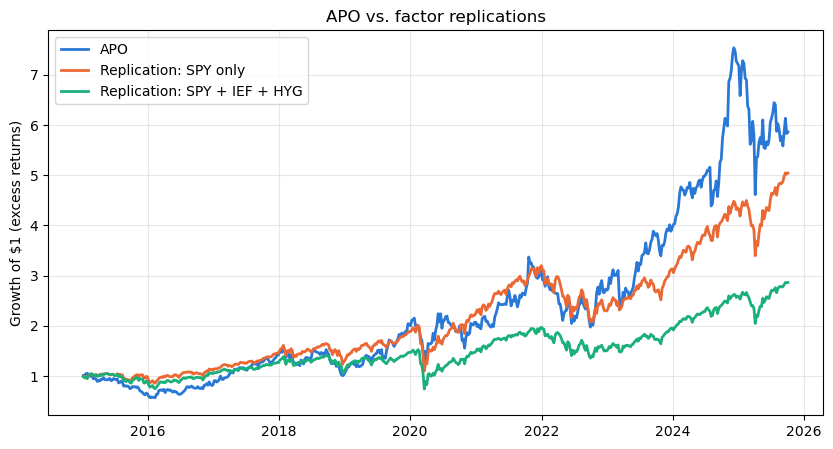

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(apo.index, (1 + apo).cumprod(), color="#2a78d6", lw=2, label="APO")
ax.plot(apo.index, (1 + reps["SPY only"]).cumprod(), color="#eb6834", lw=2, label="Replication: SPY only")
ax.plot(apo.index, (1 + reps["SPY + IEF + HYG"]).cumprod(), color="#1baf7a", lw=2, label="Replication: SPY + IEF + HYG")
ax.set_ylabel("Growth of $1 (excess returns)")
ax.set_title("APO vs. factor replications")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

_Answer:_ Only partly. The regression puts weights of about 1.07 on SPY, -0.70 on IEF and 0.93 on HYG, and all three are significant. Being long HYG and short IEF is basically a bet on credit spreads, which makes sense for PE firms since buyouts depend on cheap credit. But the R-squared is still only 0.50, so about half of APO's weekly moves have nothing to do with these factors, and the tracking error is 26% a year. The factor-only portfolio (just the betas, no alpha) earns 13.19% a year with 25.92% vol, vs. 23.15% and 36.79% for APO, so it doesn't come close to APO's return either. Running it without an intercept gives almost the same weights.

Compared to SPY alone, adding IEF and HYG only moves the R-squared from 0.47 to 0.50 and the tracking error from 26.9% to 26.1%, so the fit is only a little better. The SPY beta drops from 1.48 to 1.07 because HYG is pretty correlated with SPY (0.75) and picks up part of the equity exposure. The odd part is that the 3-factor replication actually earns less than the SPY-only one (13.19% vs. 18.22%). That's mostly because the SPY beta got smaller, and the bond legs don't make up for it since IEF and HYG both had slightly negative excess returns over this sample and roughly cancel out. Because of that, the alpha goes up from 4.9% to 10.0%, but neither alpha is significant (t-stats of 0.6 and 1.2). So SPY, IEF and HYG explain a bit more of APO's risk than SPY alone, but neither one really replicates APO.